In [1]:
from speckit import compute_spectrum

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
path = '/Users/saruul/Desktop/rp_ads1278/logged_files/Thermometer_V2/8channels_38.3_30/test_thermometer2.csv'

df = pd.read_csv(path)

channels = [c for c in df.columns if c.startswith('ch')]


In [4]:
skip = ['ch4']

channels = [c for c in channels if c not in skip]
channels

['ch1', 'ch2', 'ch3', 'ch5', 'ch6', 'ch7', 'ch8']

In [5]:
t = pd.to_datetime(df['host_timestamp'], format='ISO8601')
df['time'] = (t - t.iloc[0]).dt.total_seconds()

dt = df['time'].diff().median()
fs = 1 / dt

In [6]:
fs

111111.11108461506

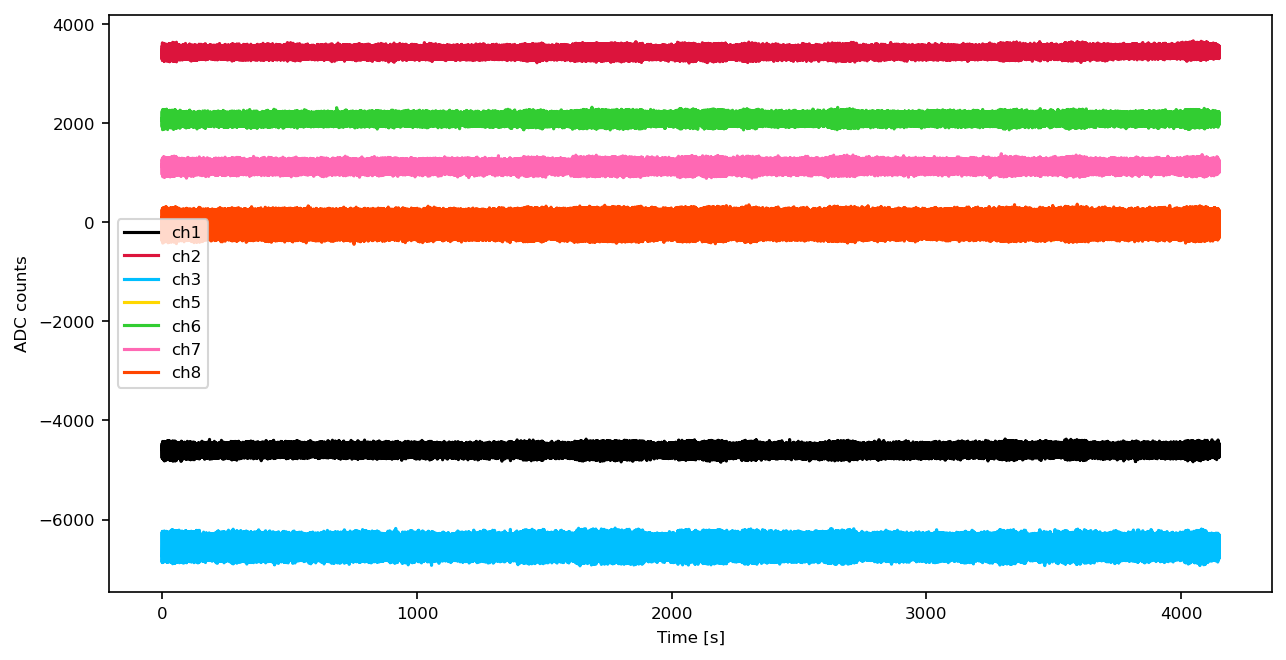

In [7]:
ax = df.plot(x='time', y=channels, figsize=(10, 5))
ax.set_xlabel('Time [s]')
ax.set_ylabel('ADC counts')
plt.show()

In [8]:
#Converting the ADC counts to voltage
vref = 2.5

for ch in channels:
    df[ch + '_V'] = df[ch] * vref / 2**23

volt_channels = [ch + '_V' for ch in channels]

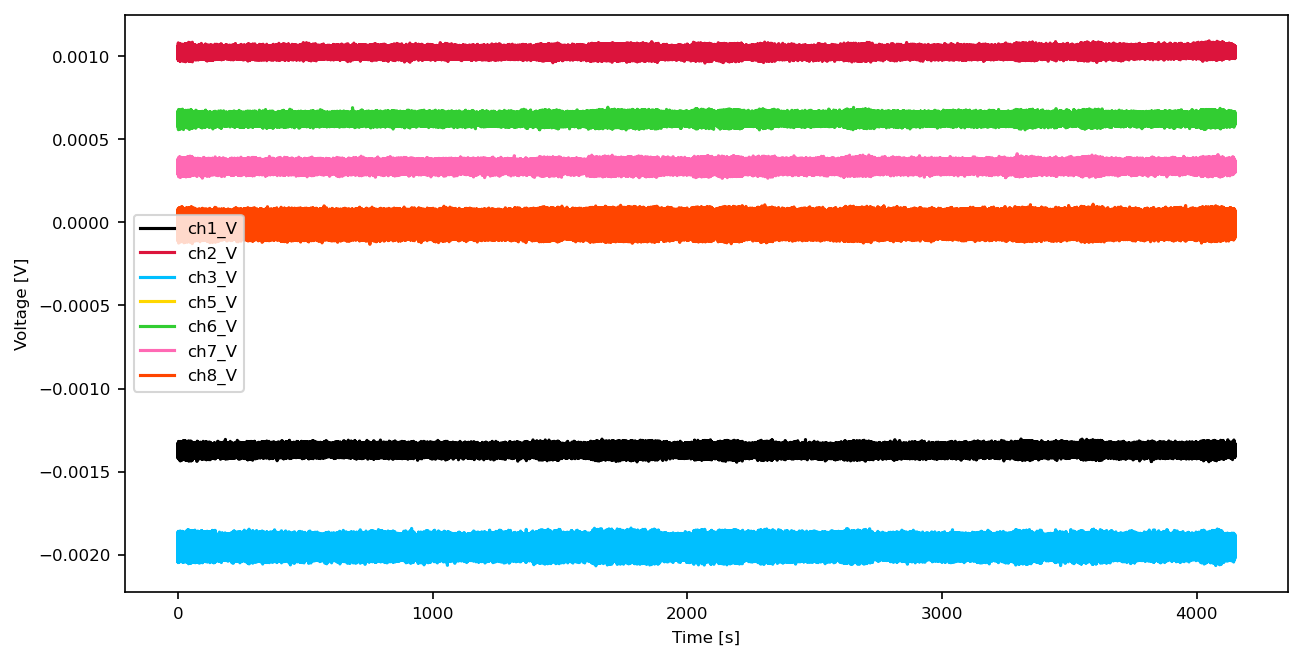

In [9]:
ax = df.plot(x='time', y=volt_channels, figsize=(10, 5))
ax.set_xlabel('Time [s]')
ax.set_ylabel('Voltage [V]')
plt.show()

In [10]:
#Computing spectrum 
ps = {}

for ch in volt_channels:
    ps[ch] = compute_spectrum(df.loc[:, ch], fs=fs, order=2)

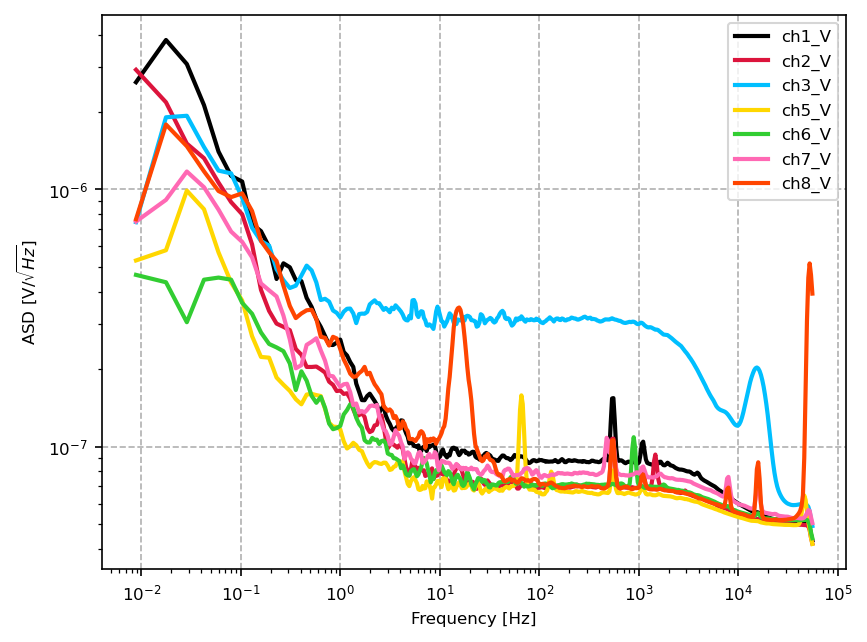

In [11]:
fig, ax = plt.subplots()

for ch in volt_channels:
    asd_K = ps[ch].asd 
    ax.loglog(ps[ch].f, asd_K, lw=2, label=ch)

ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel(r'ASD [V/$\sqrt{Hz}$]')
ax.legend()
ax.grid(True, ls='--')
plt.show()

In [12]:
#Sensitivity
beta = 4200
Vi = 1.25
T_celcius = 20
T = T_celcius + 273.15
R = 38300
R_ntc = 38300

sensitivity = (beta * Vi / T**2) * (R * R_ntc) / (R + R_ntc)**2
sensitivity

0.015272829906144245

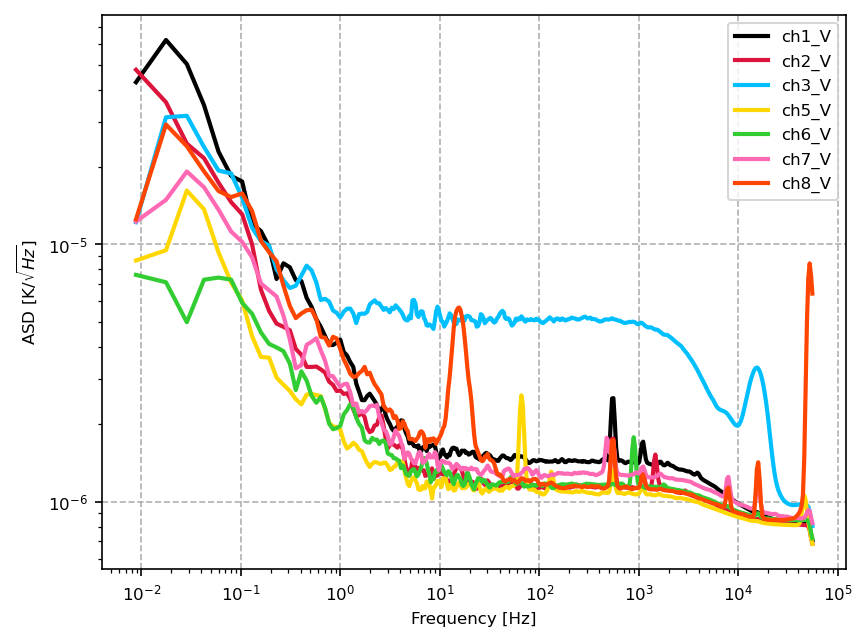

In [13]:
gain = 4

fig, ax = plt.subplots()

for ch in volt_channels:
    asd_K = ps[ch].asd / gain / sensitivity
    ax.loglog(ps[ch].f, asd_K, lw=2, label=ch)

ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel(r'ASD [K/$\sqrt{Hz}$]')
ax.legend()
ax.grid(True, ls='--')
plt.show()

In [18]:
#Print noise floor
f_min = 10
f_max = 100

for ch in volt_channels:
    f = ps[ch].f
    keep = (f >= f_min) & (f <= f_max)
    floor_V = np.median(ps[ch].asd[keep])
    floor_K = floor_V / gain / sensitivity
    print(ch)
    print(f'{floor_V:.3e} V/sqrt(Hz)')
    print(f'{floor_K:.3e} K/sqrt(Hz)')

ch1_V
9.146e-08 V/sqrt(Hz)
1.497e-06 K/sqrt(Hz)
ch2_V
7.231e-08 V/sqrt(Hz)
1.184e-06 K/sqrt(Hz)
ch3_V
3.114e-07 V/sqrt(Hz)
5.098e-06 K/sqrt(Hz)
ch5_V
6.925e-08 V/sqrt(Hz)
1.133e-06 K/sqrt(Hz)
ch6_V
7.271e-08 V/sqrt(Hz)
1.190e-06 K/sqrt(Hz)
ch7_V
8.137e-08 V/sqrt(Hz)
1.332e-06 K/sqrt(Hz)
ch8_V
8.848e-08 V/sqrt(Hz)
1.448e-06 K/sqrt(Hz)


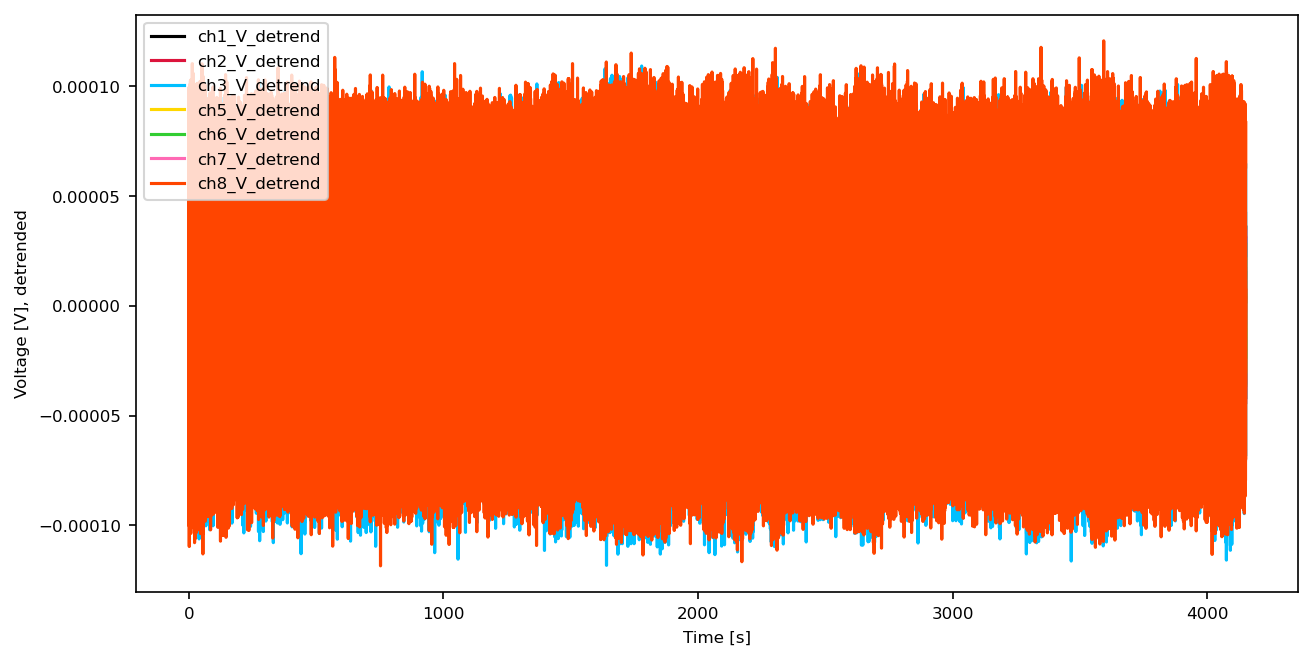

In [19]:
#Detrended toime series
for ch in volt_channels:
    coef = np.polynomial.polynomial.polyfit(df['time'], df[ch], 2)
    trend = np.polynomial.polynomial.polyval(df['time'], coef)
    df[ch + '_detrend'] = df[ch] - trend

detrended = [ch + '_detrend' for ch in volt_channels]

ax = df.plot(x='time', y=detrended, figsize=(10, 5))
ax.set_xlabel('Time [s]')
ax.set_ylabel('Voltage [V], detrended')
plt.show()